# 03 · RFM Segmentation (K-Means) & CLV
แบ่งครัวเรือนตามพฤติกรรมการซื้อด้วย **RFM + K-Means** แล้วประเมิน **Customer Lifetime Value**
และตอบคำถามวิเคราะห์ข้อ 1–2:

1. ลูกค้ากลุ่มใดใช้จ่ายเพิ่มขึ้นหรือลดลงตามเวลา?
2. แต่ละกลุ่มมีส่วนร่วมกับหมวดสินค้าใดมากขึ้นหรือน้อยลง?

In [1]:
import sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import config
from src.viz import setup, save, seg_palette, PRIMARY, ACCENT, MUTED
setup()
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
pd.set_option("display.width", 160)

In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

from src.data import load, load_transactions_clean
from src.features import build_rfm, score_rfm, build_clv, label_segments, log_scale

tx = load_transactions_clean()
ORDER, TH = config.SEGMENT_ORDER, config.SEGMENT_TH

## 1. สร้าง RFM
| ตัวแปร | นิยาม |
|---|---|
| **Recency** | จำนวนวันนับจากการซื้อครั้งล่าสุดถึงวันสุดท้ายของข้อมูล (วันที่ 711) — น้อย = ดี |
| **Frequency** | จำนวนตะกร้า (ครั้งที่มาซื้อ) ใน 2 ปี |
| **Monetary** | ยอดซื้อรวมใน 2 ปี ($) |

In [3]:
rfm = score_rfm(build_rfm(tx))
assert len(rfm) == 2500
rfm[["recency", "frequency", "monetary", "baskets_per_week", "avg_basket"]].describe().T

,count,mean,std,min,25%,50%,75%,max
recency,"2,500.00",26.58,62.79,1.00,2.00,7.00,21.00,658.00
frequency,"2,500.00",110.22,115.27,1.00,38.00,78.00,142.00,"1,298.00"
monetary,"2,500.00","3,222.98","3,349.03",8.17,970.74,"2,157.75","4,413.32","38,319.79"
baskets_per_week,"2,500.00",1.19,1.25,0.01,0.41,0.84,1.54,14.42
avg_basket,"2,500.00",31.73,19.12,2.39,18.43,27.49,40.62,165.83


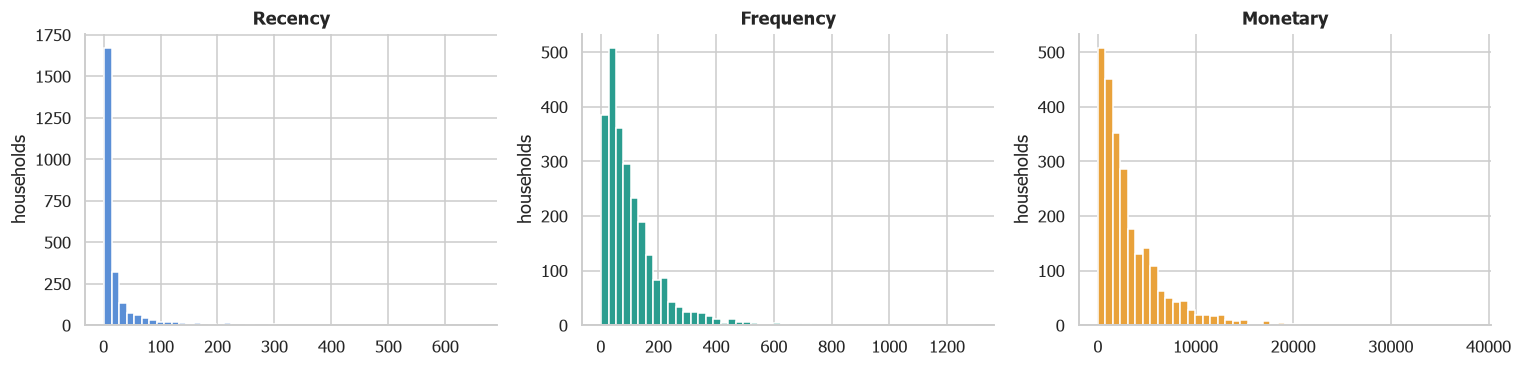

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, col, color in zip(axes, ["recency", "frequency", "monetary"], [PRIMARY, ACCENT, "#e9a23b"]):
    ax.hist(rfm[col], bins=50, color=color)
    ax.set(title=col.capitalize(), ylabel="households")
plt.tight_layout()
save(fig, "03_rfm_distributions")
plt.show()

ทั้ง 3 ตัวแปร **เบ้ขวามาก** (ลูกค้าส่วนน้อยซื้อบ่อย/ยอดสูงมาก) → ใช้ `log1p` ก่อน standardize
เพื่อไม่ให้ค่าสุดโต่งครอบงำ K-Means

## 2. เลือกจำนวนกลุ่ม (k)

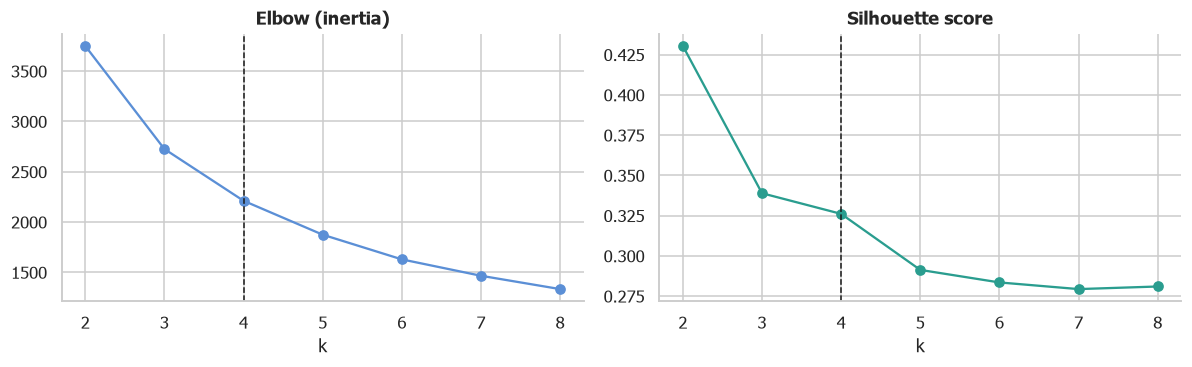

,inertia,silhouette
k,,
2,"3,750.20",0.43
3,"2,725.65",0.34
4,"2,211.25",0.33
5,"1,873.99",0.29
6,"1,628.71",0.28
7,"1,465.76",0.28
8,"1,333.23",0.28


In [5]:
X = StandardScaler().fit_transform(log_scale(rfm, ["recency", "frequency", "monetary"]))

ks = range(2, 9)
scores = []
for k in ks:
    km = KMeans(n_clusters=k, random_state=config.RANDOM_STATE, n_init=10).fit(X)
    scores.append({"k": k, "inertia": km.inertia_, "silhouette": silhouette_score(X, km.labels_)})
scores = pd.DataFrame(scores).set_index("k")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(scores.index, scores.inertia, "o-", color=PRIMARY); axes[0].set(title="Elbow (inertia)", xlabel="k")
axes[1].plot(scores.index, scores.silhouette, "o-", color=ACCENT); axes[1].set(title="Silhouette score", xlabel="k")
for ax in axes:
    ax.axvline(4, color="k", ls="--", lw=1)
plt.tight_layout()
save(fig, "03_choose_k")
plt.show()
scores

**เลือก k = 4**
- Elbow เริ่มหักที่ k = 3–4 และ silhouette ของ k = 4 (~0.33) ใกล้เคียง k = 3 (~0.34)
- k = 4 ได้กลุ่มที่ **แยกความหมายทางธุรกิจได้ชัด** และตรงกับ STP ในสไลด์
  (k = 3 จะรวมกลุ่ม "เริ่มห่างหาย" เข้ากับ "ซื้อซ้ำ" ทำให้ไม่เห็นกลุ่มที่ต้องดึงกลับ)

In [6]:
km = KMeans(n_clusters=4, random_state=config.RANDOM_STATE, n_init=10).fit(X)
rfm["cluster"] = km.labels_
rfm["segment"] = label_segments(rfm)
assert rfm.segment.notna().all() and rfm.segment.nunique() == 4

profile = rfm.groupby("segment").agg(
    households=("recency", "size"),
    recency_days=("recency", "median"),
    frequency=("frequency", "median"),
    monetary=("monetary", "median"),
    avg_basket=("avg_basket", "median"),
    baskets_per_week=("baskets_per_week", "median"),
    total_sales=("monetary", "sum"),
).reindex(ORDER)
profile["% households"] = profile.households / profile.households.sum() * 100
profile["% sales"] = profile.total_sales / profile.total_sales.sum() * 100
profile.insert(0, "ชื่อกลุ่ม", [TH[s] for s in profile.index])
assert profile.households.sum() == 2500
profile

,ชื่อกลุ่ม,households,recency_days,frequency,monetary,avg_basket,baskets_per_week,total_sales,% households,% sales
segment,,,,,,,,,,
Champions,ประจำ / มูลค่าสูง,916,3.00,165.00,"5,250.66",30.49,1.80,"5,683,945.14",36.64,70.54
Loyal,ซื้อซ้ำ / มูลค่าปานกลาง,647,4.00,57.00,"1,461.82",25.64,0.62,"1,029,985.81",25.88,12.78
At Risk,เริ่มห่างหาย,575,23.00,57.00,"1,728.53",28.70,0.63,"1,212,382.01",23.00,15.05
Occasional,ซื้อเป็นครั้งคราว,362,55.50,15.00,312.94,20.20,0.17,"131,130.84",14.48,1.63


## 3. ลักษณะแต่ละกลุ่ม

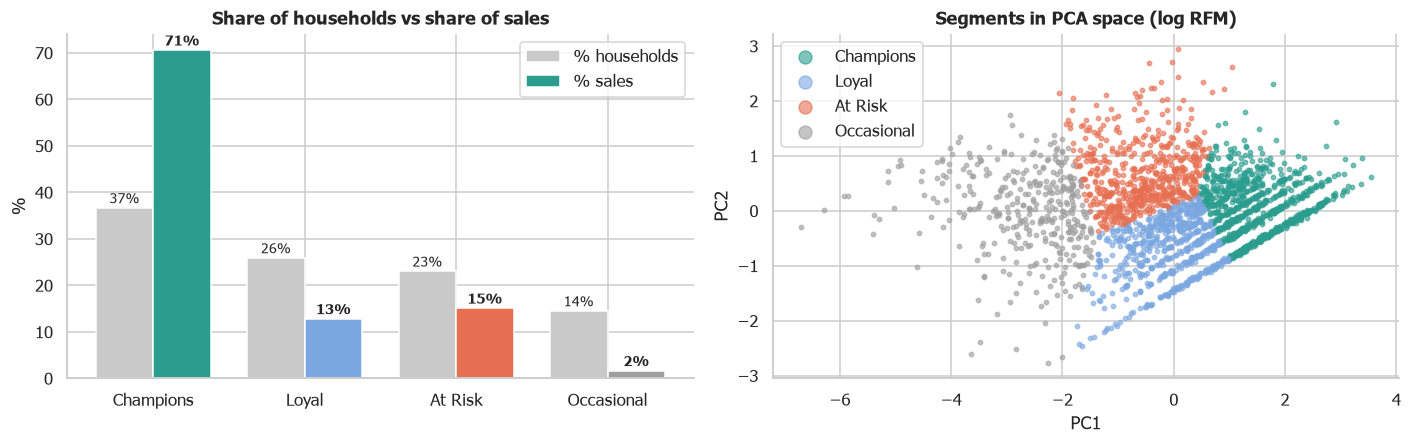

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
x = np.arange(len(ORDER)); w = .38
axes[0].bar(x - w / 2, profile["% households"], w, label="% households", color=MUTED)
axes[0].bar(x + w / 2, profile["% sales"], w, label="% sales", color=seg_palette())
for i, (a, b) in enumerate(zip(profile["% households"], profile["% sales"])):
    axes[0].text(i - w / 2, a + 1, f"{a:.0f}%", ha="center", fontsize=9)
    axes[0].text(i + w / 2, b + 1, f"{b:.0f}%", ha="center", fontsize=9, fontweight="bold")
axes[0].set_xticks(x, ORDER); axes[0].set(title="Share of households vs share of sales", ylabel="%")
axes[0].legend()

pcs = PCA(2, random_state=0).fit_transform(X)
for s in ORDER:
    m = rfm.segment.values == s
    axes[1].scatter(pcs[m, 0], pcs[m, 1], s=8, alpha=.6, color=config.SEGMENT_COLORS[s], label=s)
axes[1].set(title="Segments in PCA space (log RFM)", xlabel="PC1", ylabel="PC2")
axes[1].legend(markerscale=3)
plt.tight_layout()
save(fig, "03_segments_overview")
plt.show()

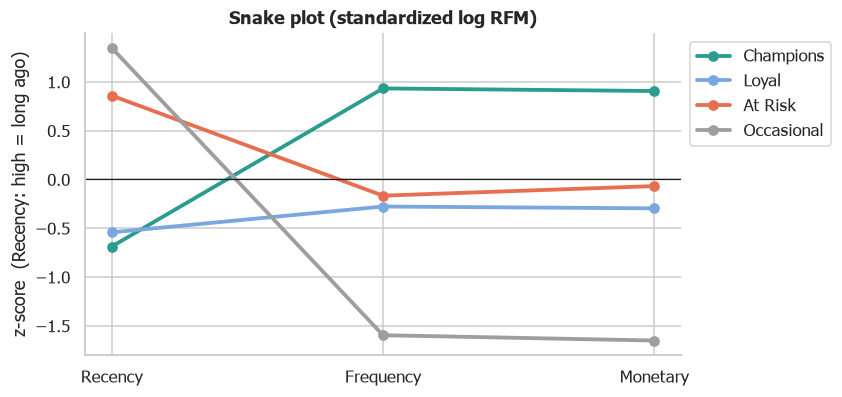

In [8]:
# Snake plot: standardized RFM means per segment
z = pd.DataFrame(X, columns=["Recency", "Frequency", "Monetary"], index=rfm.index).assign(segment=rfm.segment)
snake = z.groupby("segment").mean().reindex(ORDER)
fig, ax = plt.subplots(figsize=(7, 3.8))
for s in ORDER:
    ax.plot(snake.columns, snake.loc[s], "o-", color=config.SEGMENT_COLORS[s], lw=2.5, label=s)
ax.axhline(0, color="k", lw=.8)
ax.set(title="Snake plot (standardized log RFM)", ylabel="z-score  (Recency: high = long ago)")
ax.legend(bbox_to_anchor=(1, 1))
save(fig, "03_snake_plot")
plt.show()

| กลุ่ม | ลักษณะ |
|---|---|
| **Champions** — ประจำ / มูลค่าสูง | ซื้อเกือบ 2 ครั้ง/สัปดาห์ ซื้อล่าสุดไม่กี่วันก่อน · 37% ของครัวเรือนแต่ทำยอด **~70%** |
| **Loyal** — ซื้อซ้ำ / มูลค่าปานกลาง | ยังซื้ออยู่ (recency ต่ำ) แต่มาราว 1 ครั้งทุก 2 สัปดาห์ ตะกร้าเล็ก |
| **At Risk** — เริ่มห่างหาย | เคยซื้อพอ ๆ กับ Loyal แต่ **ไม่ได้มาซื้อ ~3 สัปดาห์** |
| **Occasional** — ซื้อเป็นครั้งคราว | ซื้อน้อยครั้ง ยอดต่ำ หายไปเกือบ 2 เดือน · 14% ของครัวเรือน แต่ ~2% ของยอด |

### RFM score (rule-based) เทียบกับ K-Means
RFM score แบบ quintile (1–5) ใช้อธิบายง่ายกับทีมการตลาด — ตรวจว่าสอดคล้องกับ cluster

In [9]:
pd.crosstab(rfm.segment, rfm.RFM_score).reindex(ORDER)

RFM_score,3,4,5,6,7,8,9,10,11,12,13,14,15
segment,,,,,,,,,,,,,
Champions,0,0,0,0,0,0,1,53,134,208,179,196,145
Loyal,0,3,30,51,108,117,137,125,63,13,0,0,0
At Risk,2,42,104,111,111,77,73,44,11,0,0,0,0
Occasional,216,105,34,5,2,0,0,0,0,0,0,0,0


## 4. ข้อมูลประชากรของแต่ละกลุ่ม (801 ครัวเรือน)
cluster ด้วยพฤติกรรมของทั้ง 2,500 ครัวเรือน แล้วใช้ข้อมูลประชากร **อธิบาย** กลุ่มภายหลัง

In [10]:
demo = load("hh_demographic").set_index("household_key").join(rfm.segment, how="inner")
print(f"households with demographics: {len(demo)}")
coverage = pd.DataFrame({"with demographics": demo.segment.value_counts(),
                         "segment size": rfm.segment.value_counts()}).reindex(ORDER).fillna(0).astype(int)
coverage["coverage %"] = coverage.iloc[:, 0] / coverage.iloc[:, 1] * 100
display(coverage)
for col in ["classification_1", "classification_3", "KID_CATEGORY_DESC", "HOMEOWNER_DESC"]:
    ct = pd.crosstab(demo.segment, demo[col], normalize="index").reindex(ORDER) * 100
    display(ct.round(0).style.format("{:.0f}").set_caption(f"{col} (% of segment)").background_gradient(axis=1, cmap="Blues"))

households with demographics: 801


,with demographics,segment size,coverage %
segment,,,
Champions,580,916,63.32
Loyal,111,647,17.16
At Risk,110,575,19.13
Occasional,0,362,0.00


classification_1,Age Group1,Age Group2,Age Group3,Age Group4,Age Group5,Age Group6
segment,,,,,,
Champions,6,18,25,37,8,7
Loyal,5,15,22,35,6,17
At Risk,5,18,24,33,6,14
Occasional,nan,nan,nan,nan,nan,nan


classification_3,Level1,Level10,Level11,Level12,Level2,Level3,Level4,Level5,Level6,Level7,Level8,Level9
segment,,,,,,,,,,,,
Champions,7,2,1,2,8,10,21,25,11,4,5,4
Loyal,9,1,0,1,11,7,22,25,16,3,2,4
At Risk,7,0,0,0,14,10,25,16,14,5,7,3
Occasional,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan


KID_CATEGORY_DESC,1,2,3+,None/Unknown
segment,,,,
Champions,15,8,8,68
Loyal,14,6,9,71
At Risk,13,4,9,75
Occasional,nan,nan,nan,nan


HOMEOWNER_DESC,Homeowner,Probable Owner,Probable Renter,Renter,Unknown
segment,,,,,
Champions,63,1,1,6,29
Loyal,68,3,2,5,23
At Risk,60,2,1,3,35
Occasional,nan,nan,nan,nan,nan


**ข้อสังเกตสำคัญ:** ข้อมูลประชากรเก็บจาก **Champions เป็นหลัก (~63% ของ Champions)** แต่มีเพียง ~17–19% ของ Loyal/At Risk
และ **ไม่มีเลยใน Occasional** — แปลว่าข้อมูลประชากรเอนเอียงไปทางลูกค้าที่ซื้อบ่อย
จึงไม่ควรใช้ข้อมูลประชากรสรุปภาพรวมลูกค้า และเป็นเหตุผลที่ cluster ด้วยพฤติกรรมการซื้อแทน

## 5. Q1 — กลุ่มไหนใช้จ่ายเพิ่มขึ้นหรือลดลงตามเวลา?

**ข้อควรระวัง:** กลุ่มด้านบนถูกกำหนดจาก Recency ณ **สิ้นข้อมูล** — At Risk คือคนที่ "เพิ่งหายไป" โดยนิยาม
ถ้าเทียบยอดซื้อครึ่งแรก vs ครึ่งหลังของกลุ่มเหล่านี้ ยอดครึ่งหลังของ At Risk จะต่ำอยู่แล้ว (circular)
จึงใช้เป็นหลักฐานว่ากลุ่มนี้ "กำลังหลุด" ไม่ได้

**วิธีที่ใช้แทน (forward-looking validation):** ทำ RFM + K-Means ซ้ำด้วย **ข้อมูลถึงสัปดาห์ที่ 59 เท่านั้น**
แล้วดูว่าแต่ละกลุ่ม *ทำอะไรต่อ* ในสัปดาห์ 60–102 ซึ่งโมเดลไม่เคยเห็น

week 59 ends on DAY 411


,recency_days,frequency,monetary,households
segment,,,,
Champions,2.00,96.00,"2,971.94",860
Loyal,5.00,35.00,955.93,848
At Risk,30.00,20.00,518.20,520
Occasional,101.00,6.00,114.70,269


,households,weekly sales wk17-59 ($),weekly sales wk60-102 ($),change %,% with no purchase in last 8 weeks
segment,,,,,
Champions,796,"55,827.81","53,380.37",-4.38,3.52
Loyal,778,"15,417.21","19,940.23",29.34,7.97
At Risk,473,"5,524.80","7,102.34",28.55,17.34
Occasional,240,430.14,"1,633.02",279.65,35.00


segment,Champions,Loyal,At Risk,Occasional
segment,,,,
Champions,85,2,13,0
Loyal,19,43,32,6
At Risk,4,40,33,22
Occasional,0,21,6,73


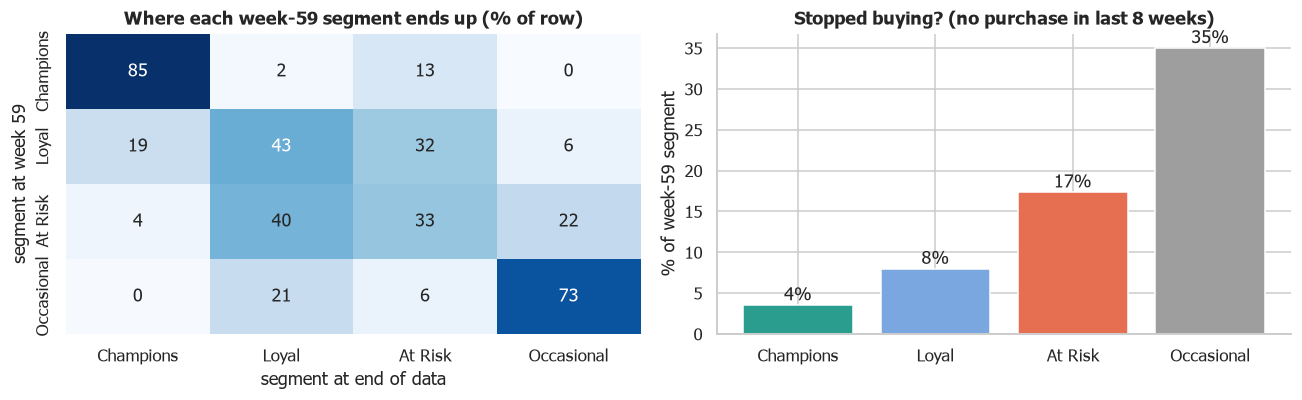

In [11]:
CUT_WEEK = 59
# WEEK_NO is not aligned to 7-day blocks of DAY, so take the cut-off day from the data
CUT_DAY = int(tx.loc[tx.WEEK_NO <= CUT_WEEK, "DAY"].max())
assert tx.loc[tx.DAY <= CUT_DAY, "WEEK_NO"].max() == CUT_WEEK
print(f"week {CUT_WEEK} ends on DAY {CUT_DAY}")

# Same method as above, but using only data up to week 59
r1 = build_rfm(tx[tx.DAY <= CUT_DAY], snapshot_day=CUT_DAY + 1)
X1 = StandardScaler().fit_transform(log_scale(r1, ["recency", "frequency", "monetary"]))
r1["cluster"] = KMeans(n_clusters=4, random_state=config.RANDOM_STATE, n_init=10).fit_predict(X1)
r1["segment"] = label_segments(r1)
assert r1.segment.nunique() == 4
display(r1.groupby("segment")[["recency", "frequency", "monetary"]].median().reindex(ORDER)
        .assign(households=r1.segment.value_counts()).rename(columns={"recency": "recency_days"}))

# Households already in the system when the H1 window starts (week 17)
in_system = r1.first_day <= tx.loc[tx.WEEK_NO == 17, "DAY"].min()
h1 = tx[tx.WEEK_NO.between(17, CUT_WEEK)].groupby("household_key").SALES_VALUE.sum()
h2 = tx[tx.WEEK_NO > CUT_WEEK].groupby("household_key").SALES_VALUE.sum()
last_day = tx.groupby("household_key").DAY.max()

fwd = pd.DataFrame({"H1": h1, "H2": h2}).reindex(r1.index).fillna(0)
fwd["segment"] = r1.segment
fwd["lapsed"] = last_day.reindex(r1.index) <= config.MAX_DAY - 56   # nothing bought in the last 8 weeks
fwd = fwd[in_system]

summary = fwd.groupby("segment").agg(households=("H1", "size"), H1=("H1", "sum"), H2=("H2", "sum"),
                                     lapsed=("lapsed", "mean")).reindex(ORDER)
summary["weekly sales wk17-59 ($)"] = summary.H1 / 43
summary["weekly sales wk60-102 ($)"] = summary.H2 / 43
summary["change %"] = (summary.H2 / summary.H1 - 1) * 100
summary["% with no purchase in last 8 weeks"] = summary.lapsed * 100
summary = summary.drop(columns=["H1", "H2", "lapsed"])
display(summary)

migr = (pd.crosstab(r1.segment, rfm.segment.reindex(r1.index), normalize="index")
        .reindex(index=ORDER, columns=ORDER) * 100)
display(migr.round(0).style.format("{:.0f}").set_caption("% of week-59 segment ending in each final segment"))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
sns.heatmap(migr, annot=True, fmt=".0f", cmap="Blues", cbar=False, ax=axes[0])
axes[0].set(title="Where each week-59 segment ends up (% of row)", xlabel="segment at end of data", ylabel="segment at week 59")
lapse = summary["% with no purchase in last 8 weeks"]
axes[1].bar(ORDER, lapse, color=seg_palette())
for i, v in enumerate(lapse):
    axes[1].text(i, v + .6, f"{v:.0f}%", ha="center")
axes[1].set(title="Stopped buying? (no purchase in last 8 weeks)", ylabel="% of week-59 segment")
plt.tight_layout()
save(fig, "03_forward_validation")
plt.show()

summary.to_parquet(config.PROCESSED_DIR / "forward_validation.parquet")
migr.to_parquet(config.PROCESSED_DIR / "migration.parquet")

**ผล Q1 (ทดสอบกับข้อมูลที่โมเดลไม่เคยเห็น):**
- **Champions เสถียรที่สุด** — ยอดครึ่งหลังเปลี่ยน ~−4% และ **~85% ยังเป็น Champions เมื่อสิ้นข้อมูล** แต่ **~13% ตกลงไปเป็น At Risk**
- กลุ่มอื่น **เลื่อนเข้าหาค่ากลาง** (Loyal +29%, At Risk +29%, Occasional +280% จากฐานเล็กมาก ~$0.4K/สัปดาห์)
  นี่คือ regression to the mean — กลุ่มถูกนิยามจากยอดช่วงเดียวกับครึ่งแรก ไม่ควรตีความว่า "กลุ่มนี้กำลังโต"
- **At Risk เป็นสัญญาณเตือนจริงแต่ไม่แม่นพอ:** กลุ่มนี้ไม่มาซื้อเลยใน 8 สัปดาห์สุดท้ายถึง **~17%** (Loyal ~8%, Champions ~4%)
  แต่ **~83% ยังกลับมาซื้อ** และยอดรวมของกลุ่มเพิ่มขึ้น → การส่งโปรแรงให้ทุกคนใน At Risk จะส่งโดนคนที่จะกลับมาเองเป็นส่วนใหญ่
  ต้องมีโมเดล churn คัดเฉพาะคนที่เสี่ยงจริง (ขั้นต่อไปตามแผน)

## 6. Q2 — แต่ละกลุ่มซื้อหมวดสินค้าใดมากขึ้นหรือน้อยลง?
ใช้กลุ่มจากสัปดาห์ที่ 59 (out-of-sample เช่นเดียวกัน) ดูการเปลี่ยนของ **สัดส่วนหมวดในยอดซื้อ** ระหว่างครึ่งแรกกับครึ่งหลัง (percentage point)

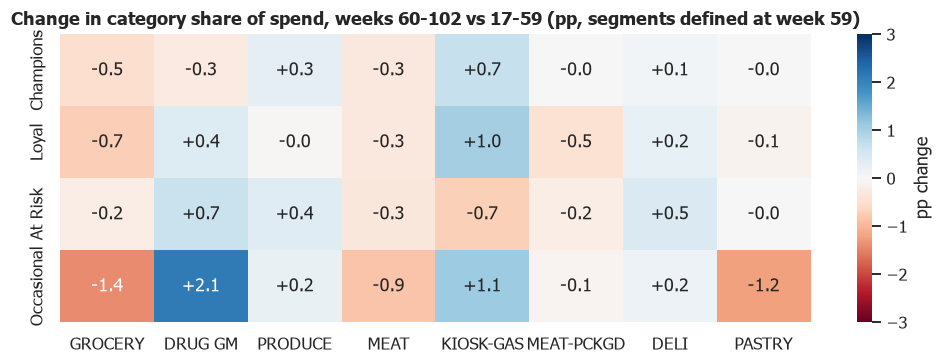

DEPARTMENT,GROCERY,DRUG GM,PRODUCE,MEAT,KIOSK-GAS,MEAT-PCKGD,DELI,PASTRY
segment,,,,,,,,
Champions,53.10,14.20,7.30,6.90,8.40,5.10,3.40,1.50
Loyal,56.20,13.20,7.80,7.90,3.60,5.80,3.50,2.00
At Risk,55.40,12.90,6.90,8.20,5.00,6.40,3.40,1.80
Occasional,54.90,14.20,7.80,6.80,4.10,6.50,3.10,2.50


In [12]:
top_depts = tx.groupby("DEPARTMENT").SALES_VALUE.sum().nlargest(8).index
sub = tx[tx.WEEK_NO.between(17, config.N_WEEKS) & tx.household_key.isin(fwd.index)
         & tx.DEPARTMENT.isin(top_depts)].copy()
sub["period"] = np.where(sub.WEEK_NO <= CUT_WEEK, "H1", "H2")
sub["early_segment"] = sub.household_key.map(r1.segment)
share = sub.groupby(["early_segment", "period", "DEPARTMENT"]).SALES_VALUE.sum()
share = share / share.groupby(level=[0, 1]).transform("sum") * 100
shift = (share.xs("H2", level="period") - share.xs("H1", level="period")).unstack().reindex(ORDER)[top_depts]

fig, ax = plt.subplots(figsize=(11, 3.4))
sns.heatmap(shift, annot=True, fmt="+.1f", cmap="RdBu", center=0, vmin=-3, vmax=3, ax=ax,
            cbar_kws={"label": "pp change"})
ax.set(title="Change in category share of spend, weeks 60-102 vs 17-59 (pp, segments defined at week 59)",
       xlabel="", ylabel="")
save(fig, "03_category_shift")
plt.show()

# Static view: what each (final) segment buys
cur = tx[tx.DEPARTMENT.isin(top_depts)].assign(segment=lambda d: d.household_key.map(rfm.segment))
mix = (cur.groupby(["segment", "DEPARTMENT"]).SALES_VALUE.sum()
       / cur.groupby("segment").SALES_VALUE.sum() * 100).unstack().reindex(ORDER)[top_depts]
mix.round(1)

**ผล Q2:**
- **โครงสร้างหมวดของแต่ละกลุ่มนิ่งมาก** — เกือบทุกช่องเปลี่ยนไม่เกิน ~1 pp (Occasional ผันผวนกว่าเพราะฐานเล็ก ไม่ควรตีความ)
  ไม่พบหมวดใดที่กลุ่มใดกำลังซื้อมากขึ้นหรือน้อยลงอย่างชัดเจน
- **GROCERY เป็นหมวดหลักของทุกกลุ่ม (~53–56%)** → เลือกหมวดสำหรับโปรจาก "ตะกร้าปัจจุบัน" ของแต่ละกลุ่ม ไม่ใช่จากแนวโน้มการเปลี่ยน
- **Champions มีสัดส่วนน้ำมัน (KIOSK-GAS) สูงกว่ากลุ่มอื่นชัดเจน (~8% เทียบ ~4–5%)** — ส่วนหนึ่งของความภักดีมาจากการเติมน้ำมันที่ร้าน

## 7. Customer Lifetime Value (CLV)
ไม่มีข้อมูลต้นทุน/กำไร จึงใช้ **CLV เชิงรายได้**:
- `clv_hist` = ยอดซื้อจริงใน 2 ปี
- `clv_12m` = ยอดซื้อเฉลี่ยต่อสัปดาห์ช่วง 26 สัปดาห์ล่าสุด × 52 → คาดการณ์รายได้ 12 เดือนข้างหน้าถ้าพฤติกรรมยังเหมือนเดิม

,households,clv_hist_median,clv_12m_median,clv_12m_total,% of projected revenue
segment,,,,,
Champions,916,"5,250.66","3,050.48","3,363,211.88",71.75
Loyal,647,"1,461.82",908.16,"704,298.22",15.02
At Risk,575,"1,728.53",740.02,"557,678.78",11.90
Occasional,362,312.94,110.13,"62,537.30",1.33


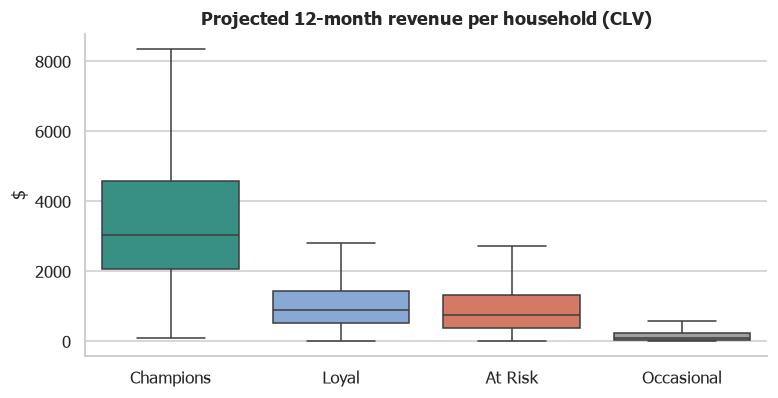

In [13]:
clv = build_clv(tx).join(rfm.segment)
clv_seg = clv.groupby("segment").agg(
    households=("clv_hist", "size"),
    clv_hist_median=("clv_hist", "median"),
    clv_12m_median=("clv_12m", "median"),
    clv_12m_total=("clv_12m", "sum"),
).reindex(ORDER)
clv_seg["% of projected revenue"] = clv_seg.clv_12m_total / clv_seg.clv_12m_total.sum() * 100
display(clv_seg)

fig, ax = plt.subplots(figsize=(8, 3.8))
sns.boxplot(data=clv, x="segment", y="clv_12m", order=ORDER, palette=seg_palette(), showfliers=False, ax=ax)
ax.set(title="Projected 12-month revenue per household (CLV)", xlabel="", ylabel="$")
save(fig, "03_clv")
plt.show()

**ผล CLV:** Champions หนึ่งครัวเรือนมีมูลค่าคาดการณ์ ~$3,050/ปี สูงกว่า Loyal ราว 3 เท่า และ At Risk ราว 4 เท่า · ทำรายได้คาดการณ์ ~72% ของทั้งหมด
- clv_12m ของ At Risk ต่ำกว่า Loyal ทั้งที่ยอดรวม 2 ปีสูงกว่า เพราะ 26 สัปดาห์ล่าสุดซื้อน้อย —
  ส่วนหนึ่งเป็นผลจากนิยามกลุ่ม (At Risk คือคนที่เพิ่งห่าง) ไม่ใช่หลักฐานว่าหลุดถาวร (ดูหัวข้อ 5)
- CLV นี้เป็นการคาดการณ์แบบง่าย (ยอดล่าสุด × 52) ไม่ได้ใส่โอกาสหยุดซื้อหรือกำไร — ใช้จัดอันดับกลุ่ม ไม่ใช่ตัวเลขพยากรณ์

In [14]:
out = rfm.join(clv[["clv_hist", "weekly_recent", "clv_12m"]])
out.to_parquet(config.PROCESSED_DIR / "segments.parquet")
print("saved segments.parquet", out.shape)

saved segments.parquet (2500, 17)


## สรุป Segmentation & CLV
| กลุ่ม | % ครัวเรือน | % ยอดขาย | หลักฐานจากการทดสอบกับข้อมูลที่ไม่เคยเห็น | แนวทาง |
|---|---|---|---|---|
| Champions | ~37% | ~71% | เสถียรที่สุด (~85% ยังเป็น Champions) · ~13% ตกไป At Risk | รักษา + ขายคู่ในหมวดหลัก · เฝ้าดูคนที่เริ่มห่าง |
| Loyal | ~26% | ~13% | กลุ่มกลาง ย้ายเข้า–ออกมาก | ทดสอบข้อเสนอเพิ่มความถี่ |
| At Risk | ~23% | ~15% | เสี่ยงหยุดซื้อ ~2 เท่าของ Loyal (17% vs 8%) แต่ ~83% ยังกลับมา | **อย่าส่งโปรแรงทุกคน** — ใช้โมเดล churn คัดคน + ทดสอบด้วย holdout |
| Occasional | ~14% | ~2% | ซื้อน้อยและห่างมาก | ช่องทางต้นทุนต่ำ |

> ตัวเลขยอดซื้อที่ "ลดลง/เพิ่มขึ้น" ของกลุ่มที่นิยามจากสิ้นข้อมูล ไม่ใช้เป็นหลักฐานแนวโน้ม เพราะเป็นผลของนิยามกลุ่มเอง